In [14]:
# Cell 1 Common for 28-31 CBOW

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import re

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Flatten
from tensorflow.keras.optimizers import Adam


In [31]:
text = """
Python is a programming language.
Python is easy to learn,
Machine learning uses python.
Deep learning uses neural networks
python is popular for machine learning
machine learning is a part of artificial intelligence
deep learning is a part of machine learning.
"""

In [32]:
# Convert to lowercase
text = text.lower()

# Remove punctuation
text = re.sub(r'[^a-z\s]', '', text)

# Tokenize
words = text.split()

print("Words:")
print(words)

Words:
['python', 'is', 'a', 'programming', 'language', 'python', 'is', 'easy', 'to', 'learn', 'machine', 'learning', 'uses', 'python', 'deep', 'learning', 'uses', 'neural', 'networks', 'python', 'is', 'popular', 'for', 'machine', 'learning', 'machine', 'learning', 'is', 'a', 'part', 'of', 'artificial', 'intelligence', 'deep', 'learning', 'is', 'a', 'part', 'of', 'machine', 'learning']


In [33]:
vocabulary= sorted(set(words))
word_to_index = {word: i for i, word in enumerate(vocabulary)}
index_to_word = {i: word for word, i in word_to_index.items()}

vocabulary_size = len(vocabulary)

print("Vocabulary:")
print(vocabulary)

print("\nVocabulary Size:", vocabulary_size)

Vocabulary:
['a', 'artificial', 'deep', 'easy', 'for', 'intelligence', 'is', 'language', 'learn', 'learning', 'machine', 'networks', 'neural', 'of', 'part', 'popular', 'programming', 'python', 'to', 'uses']

Vocabulary Size: 20


In [34]:
#Common for chits but for 28 chit
window_size = 2
X = []
y = []

for i in range(window_size, len(words) - window_size):
    context = []
    for j in range(i - window_size, i + window_size + 1):
        if j != i:
            context.append(word_to_index[words[j]])

    target = word_to_index[words[i]]

    X.append(context)
    y.append(target)

X = np.array(X)
y = np.array(y)

print("Context shape:", X.shape)
print("Target shape :", y.shape)


Context shape: (37, 4)
Target shape : (37,)


In [35]:
#for chit 28 # ==========================================================
print("\nSample CBOW Training Pairs:\n")

for i in range(5):

    context_words = [
        index_to_word[idx]
        for idx in X[i]
    ]

    target_word = index_to_word[y[i]]

    print("Context:", context_words)
    print("Target :", target_word)
    print()


Sample CBOW Training Pairs:

Context: ['python', 'is', 'programming', 'language']
Target : a

Context: ['is', 'a', 'language', 'python']
Target : programming

Context: ['a', 'programming', 'python', 'is']
Target : language

Context: ['programming', 'language', 'is', 'easy']
Target : python

Context: ['language', 'python', 'easy', 'to']
Target : is



In [36]:
model = Sequential([
    Embedding(
        input_dim=vocabulary_size,
        output_dim=10,
        input_shape=(X_indices.shape[1],)
    ),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(vocabulary_size, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)              │ (None, 4, 10)               │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_8 (Flatten)                  │ (None, 40)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 64)                  │           2,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 20)                  │           1,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,124 (16.11 KB)

 Trainable params: 4,124 (16.11 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
history = model.fit(
    X,
    y,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5405 - loss: 2.9150 
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5676 - loss: 2.9040 
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5676 - loss: 2.8929 
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5676 - loss: 2.8807 
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5676 - loss: 2.8671 
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5676 - loss: 2.8522 
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5405 - loss: 2.8364 
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5405 - loss: 2.8195 
Epoch 9/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5405 - loss: 2.7998 
Epoch 10/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5405 - loss: 2.7801 
Epoch 11/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5405 - loss: 2.7569 
Epoch 12/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5676 - los

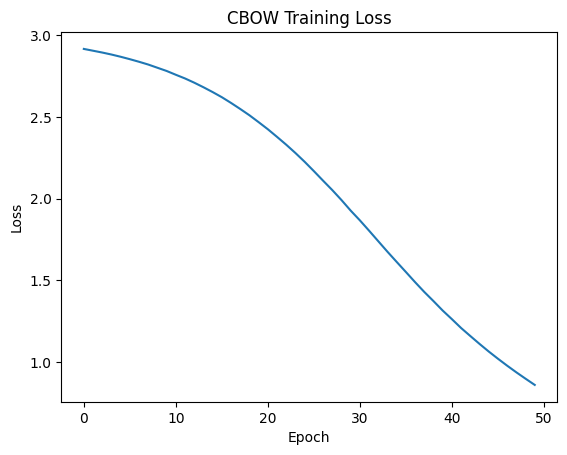

Final Training Loss: 0.8605882525444031


In [44]:
#for chit 28

plt.plot(history.history['loss'])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CBOW Training Loss")

plt.show()
print("Final Training Loss:", history.history["loss"][-1])

In [41]:
def predict_word(context_words):

    context_indices = [
        word_to_index[word]
        for word in context_words
    ]

    context_indices = np.array([context_indices])

    prediction = model.predict(context_indices, verbose=0)

    predicted_index = np.argmax(prediction)

    return index_to_word[predicted_index]

In [42]:
context = ['deep', 'learning', 'part', 'of']

predicted_word = predict_word(context)

print("Context:", context)
print("Predicted Word:", predicted_word)

Context: ['deep', 'learning', 'part', 'of']
Predicted Word: is


In [43]:
# For chit 31
embeddings = model.layers[0].get_weights()[0]

print("Learned Word Embeddings:\n")

for word, index in word_to_index.items():
    print(word, ":", embeddings[index])

Learned Word Embeddings:

a : [ 0.10658846  0.06644755  0.1865328   0.11827451  0.3147098  -0.31531358
 -0.21453664  0.16912991  0.1183861  -0.2583995 ]
artificial : [ 0.05331779 -0.06850906  0.07477888  0.15468985 -0.15951002  0.04016497
  0.1916585  -0.04837146  0.04345237 -0.12280399]
deep : [ 0.05892474 -0.00143088  0.14586882  0.25415128  0.04146263 -0.00903343
  0.13304637  0.0588907  -0.13595152 -0.2178789 ]
easy : [-0.15328777 -0.06590544 -0.1051563  -0.11197102  0.12700957 -0.05669316
  0.07869401 -0.07032518  0.03498806  0.0274738 ]
for : [-0.19276637  0.06566433  0.22665687 -0.11949371  0.04002455  0.18009377
  0.20223436 -0.06898924  0.1959122  -0.2543234 ]
intelligence : [ 0.15955307  0.13387571  0.1627847  -0.10048375 -0.03594049  0.00688798
  0.23785472 -0.08118651 -0.19784214 -0.03809027]
is : [ 0.3142091  -0.01841782  0.07522876 -0.03409498  0.34038404 -0.10776514
 -0.10285846 -0.22728321  0.30143893  0.22009078]
language : [-0.17661738  0.17363836 -0.22648932  0.18917